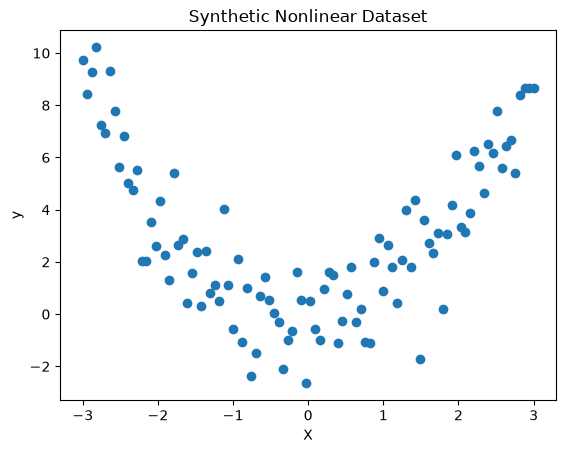

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = X[:, 0] ** 2 + np.random.normal(0, 1.5, size=100)

plt.scatter(X[:, 0], y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Synthetic Nonlinear Dataset")
plt.show()

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

degrees = [1, 2, 10, 20]
results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    results.append({
        "Degree": degree,
        "Train_MSE": train_mse,
        "Validation_MSE": val_mse
    })

results_df = pd.DataFrame(results)
print(results_df.round(2))
results_df

   Degree  Train_MSE  Validation_MSE
0       1      10.51            7.71
1       2       1.98            1.36
2      10       1.72            1.68
3      20       2.21            6.70


,Degree,Train_MSE,Validation_MSE
0,1,10.512888,7.712715
1,2,1.982708,1.360588
2,10,1.723796,1.683090
3,20,2.208443,6.704419


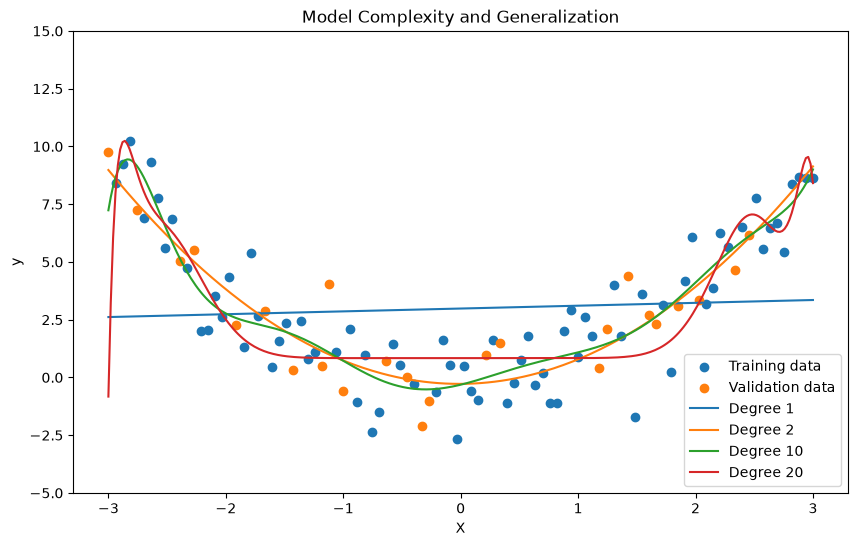

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], y_train, label="Training data")
plt.scatter(X_val[:, 0], y_val, label="Validation data")

X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

for degree in [1, 2, 10, 20]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)

    plt.plot(
        X_plot[:, 0],
        model.predict(X_plot),
        label=f"Degree {degree}"
    )

plt.ylim(-5, 15)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Model Complexity and Generalization")
plt.legend()
plt.show()